# 5. Three-Way Background Marginalization, Tempered SMC Evidence & Cornerplot (`sample_smc`)

This tutorial replaces `docs/notebooks/05_Fitting_Flat.ipynb`, where `ticktack 1.x` fitted a pure spike on a flat cosmic-ray baseline (`spike_only`) to `Miyake12_Cedar` (`Guttler15`). Because `v1`'s adaptive Runge–Kutta solver stepped clean across narrow sub-annual spikes whenever the baseline had zero solar derivative, `v1` had to disable adaptive integration (`adaptive=False`) and force `oversample=1008` fixed sub-steps per year, taking **`26.9 s`** in `emcee` while providing no Bayesian evidence $\ln Z$ to compare background models.

`ticktack 2.0`'s `ExactLinearSolver` splits integration sub-intervals analytically at the exact `MiyakeSpike` support knots via clamped [Van Loan (1978)](https://doi.org/10.1109/TAC.1978.1101743) matrix exponentials – conserving fluence to machine precision down to day-scale pulses with zero oversampling – while `BlackJAX` adaptive tempered `sample_smc` computes calibrated marginal log-evidences across three nested cosmic-ray background models: **Flat Baseline**, **HarmonicSolar (11-yr)**, and **Marginalized GP** (`GaussianField` with `QuasiPeriodicSpectrum`).

In [1]:
import math, time
import jax, jax.numpy as jnp, numpy as np
import ticktack as tt

cedar = tt.TreeRingSeries.from_csv(
    "notebooks/miyake12.csv", hemisphere="north", growth_season="april-september", name="Miyake12_Cedar"
)
ds = tt.Dataset(cedar, name="Miyake12_Flat")
cbm = tt.load_preset("Guttler15")
flat_model = tt.RadiocarbonModel(
    cbm, tt.SteadyProduction() + tt.MiyakeSpike(t_start=774.5, duration=0.25, fluence=6.5, profile="boxcar")
)
narrow_jump = float(jnp.max(flat_model.set("production.spike.duration", 0.005).predict_d14c(ds)))
broad_jump = float(jnp.max(flat_model.predict_d14c(ds)))
print(f"ExactLinearSolver peak jump without oversampling: dur=0.25 yr -> {broad_jump:.2f} permil, dur=0.005 yr -> {narrow_jump:.2f} permil")

ExactLinearSolver peak jump without oversampling: dur=0.25 yr -> 17.18 permil, dur=0.005 yr -> 17.22 permil


## Adaptive Tempered SMC on the Flat-Baseline Model vs `v1` (`26.9 s`)

Defining normalized unconstrained priors in `ParameterSpace` allows `sample_smc` to anneal particles from inverse temperature `beta = 0` (exact prior) to `beta = 1` (posterior) with multinomial resampling and [Lee & Whiteley (2018)](https://doi.org/10.1093/biomet/asy028) ancestral-lineage variance estimation (which yields a consistent single-run estimator of the normalizing-constant variance under multinomial resampling), returning both posterior samples and an unbiased log-evidence estimate.

In [2]:
specs = [
    tt.ParamSpec("production.spike.t_start", "sigmoid", 0.0, 1.2, low=773.5, high=776.0),
    tt.ParamSpec("production.spike.duration", "sigmoid", -0.5, 1.2, low=0.02, high=2.0),
    tt.ParamSpec("production.spike.fluence", "exp", math.log(6.5), 0.5),
]
ps_flat = tt.ParameterSpace(flat_model, specs)
cfg_flat = tt.LinearMarginalConfig(offset_mode="shared", marginalize_solar=False)
t0 = time.perf_counter()
smc_flat = tt.sample_smc(flat_model, ds, ps_flat, cfg_flat, num_particles=400, num_mcmc_steps=5, rng_key=jax.random.PRNGKey(501))
jax.block_until_ready(smc_flat.log_evidence)
dt_smc_cold = time.perf_counter() - t0
t1 = time.perf_counter()
smc_flat_w = tt.sample_smc(flat_model, ds, ps_flat, cfg_flat, num_particles=400, num_mcmc_steps=5, rng_key=jax.random.PRNGKey(502))
jax.block_until_ready(smc_flat_w.log_evidence)
dt_smc_warm = time.perf_counter() - t1
print(f"Flat-baseline ln Z = {float(smc_flat.log_evidence):.2f} +/- {float(smc_flat.log_evidence_err):.2f} | cold={dt_smc_cold:.2f} s ({26.9/dt_smc_cold:.1f}x vs 26.9 s v1), warm={dt_smc_warm:.2f} s ({26.9/dt_smc_warm:.1f}x)")

Flat-baseline ln Z = -68.54 +/- 0.09 | cold=5.17 s (5.2x vs 26.9 s v1), warm=0.06 s (463.1x)


## Three-Way Bayesian Model Comparison: Flat Baseline vs `HarmonicSolar` vs Marginalized GP ($\Delta\ln\widehat{Z}$)

Keeping the exact same three-parameter `MiyakeSpike` prior, we compare three analytically marginalized backgrounds via `LinearMarginalConfig`: (1) `Flat Baseline` (`marginalize_solar=False`), (2) `HarmonicSolar` (`periods=11.0`, `marginalize_solar=True`), and (3) a quasi-periodic `GaussianField` (`QuasiPeriodicSpectrum(sigma=0.30, period_yr=10.9, quality=4.0)`, `marginalize_field=True`) whose 128 DCT-II modes are marginalized in closed form at every SMC particle evaluation.

In [3]:
spike0 = tt.MiyakeSpike(t_start=774.5, duration=0.25, fluence=6.5, profile="boxcar")
solar_model = tt.RadiocarbonModel(cbm, tt.ProductionSum(steady=tt.SteadyProduction(), solar=tt.HarmonicSolar(periods=11.0, t_ref=775.0), spike=spike0))
cfg_solar = tt.LinearMarginalConfig(offset_mode="shared", solar_prior_sd=0.35, marginalize_solar=True)
smc_solar = tt.sample_smc(solar_model, ds, tt.ParameterSpace(solar_model, specs), cfg_solar, num_particles=400, num_mcmc_steps=5, rng_key=jax.random.PRNGKey(503))
gp_field = tt.GaussianField(jnp.zeros(128), 740.0, 795.0, kernel=tt.QuasiPeriodicSpectrum(sigma=0.30, period_yr=10.9, quality=4.0))
gp_model = tt.RadiocarbonModel(cbm, tt.ProductionSum(steady=tt.SteadyProduction(), field=gp_field, spike=spike0))
ps_gp, cfg_gp = tt.ParameterSpace(gp_model, specs), tt.LinearMarginalConfig(offset_mode="shared", marginalize_field=True)
smc_gp = tt.sample_smc(gp_model, ds, ps_gp, cfg_gp, num_particles=400, num_mcmc_steps=5, rng_key=jax.random.PRNGKey(505))
z0, e0 = float(smc_flat.log_evidence), float(smc_flat.log_evidence_err)
rows = [("Flat Baseline", smc_flat), ("HarmonicSolar (11-yr)", smc_solar), ("Marginalized GP (QP)", smc_gp)]
for lbl, res in rows:
    z, e = float(res.log_evidence), float(res.log_evidence_err)
    q0 = res.idata.posterior["production__spike__fluence"].values.reshape(-1) / tt.DEFAULT_Q_STD
    print(f"{lbl:22s}: ln Z = {z:6.2f} +/- {e:.2f} (Delta = {z - z0:+5.2f} +/- {math.hypot(e, e0):.2f}) | Q/q0 = {q0.mean():.2f} +/- {q0.std():.2f} yr")

Flat Baseline         : ln Z = -68.54 +/- 0.09 (Delta = +0.00 +/- 0.12) | Q/q0 = 3.43 +/- 0.17 yr
HarmonicSolar (11-yr) : ln Z = -64.72 +/- 0.08 (Delta = +3.81 +/- 0.11) | Q/q0 = 3.61 +/- 0.18 yr
Marginalized GP (QP)  : ln Z = -63.30 +/- 0.10 (Delta = +5.24 +/- 0.13) | Q/q0 = 3.49 +/- 0.41 yr


## Marginalized GP + Spike Posterior $\Delta^{14}\mathrm{C}(t)$ Trajectory and Pulls

Propagating resampled `Marginalized GP + Spike` SMC particles through `linear_posterior` shows how the quasi-periodic `GaussianField` absorbs the pre-event and post-event solar modulation smoothly while sharpening the 774–775 CE pulse residual pulls $(d - m)/\sigma$.

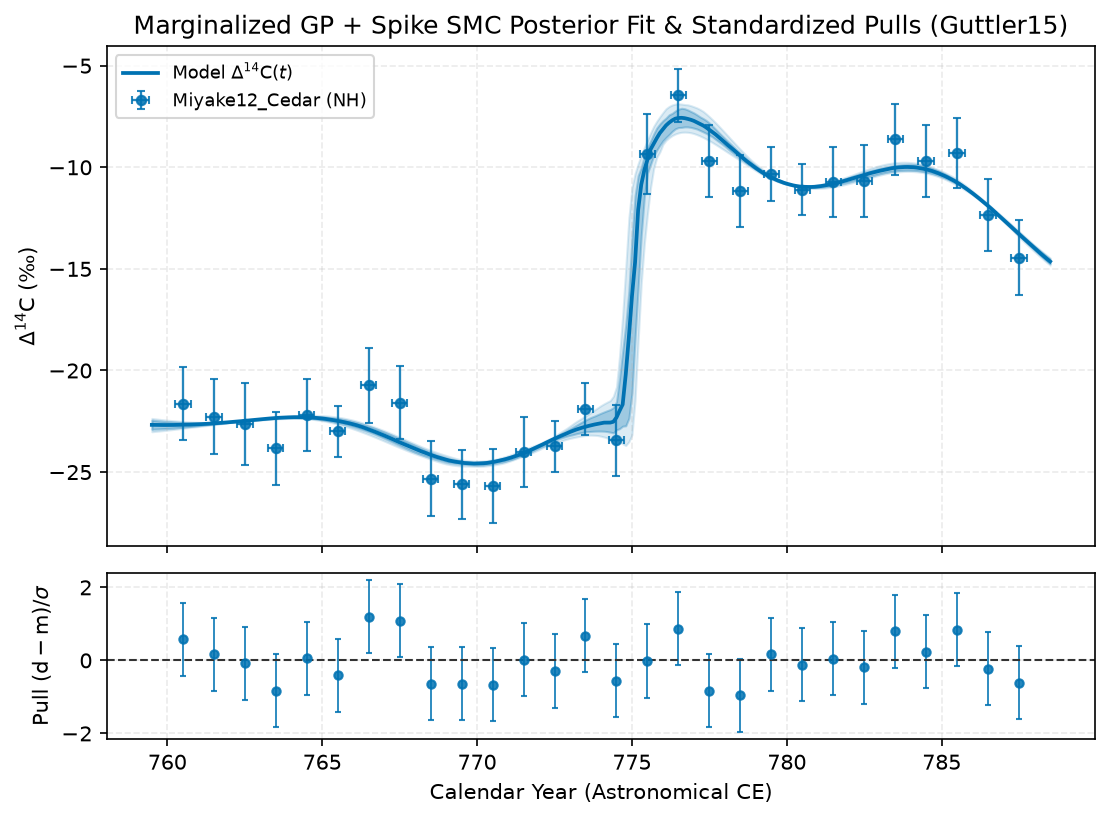

In [4]:
jax.clear_caches()
t_fine = jnp.linspace(759.5, 788.5, 291)
u_sub = smc_gp.particles[jax.random.choice(jax.random.PRNGKey(504), smc_gp.particles.shape[0], shape=(64,), p=smc_gp.weights)]
d14c_gp = jax.lax.map(lambda u: tt.linear_posterior(ps_gp.constrain(u, gp_model), ds, cfg_gp, t_fine=t_fine).d14c_fine_mean, u_sub)
u_mean = jnp.sum(smc_gp.weights[:, None] * smc_gp.particles, axis=0)
lp_gp = tt.linear_posterior(ps_gp.constrain(u_mean, gp_model), ds, cfg_gp, t_fine=t_fine)
fig_fit, axes_fit = tt.plot_d14c_fit(
    ds,
    t_fine=t_fine,
    d14c_pred=d14c_gp,
    ring_pred=lp_gp.ring_pred_mean,
    show_residuals=True,
    title="Marginalized GP + Spike SMC Posterior Fit & Standardized Pulls (Guttler15)",
)

## Three-Chain `ChainConsumer` Cornerplot: Propagating Background Uncertainty

Overlaying all three tempered SMC posteriors on a shared `tt.plot_corner(...)` grid over onset $t_{\mathrm{start}}$, duration $\tau_d$, and production-year yield $Q / q_0 = F / Q_{\mathrm{std}}$ demonstrates how replacing a rigid flat baseline with a fixed-period sinusoid or an analytically marginalized quasi-periodic GP shifts the inferred spike yield and realistically widens its credible contours to account for background solar variability.

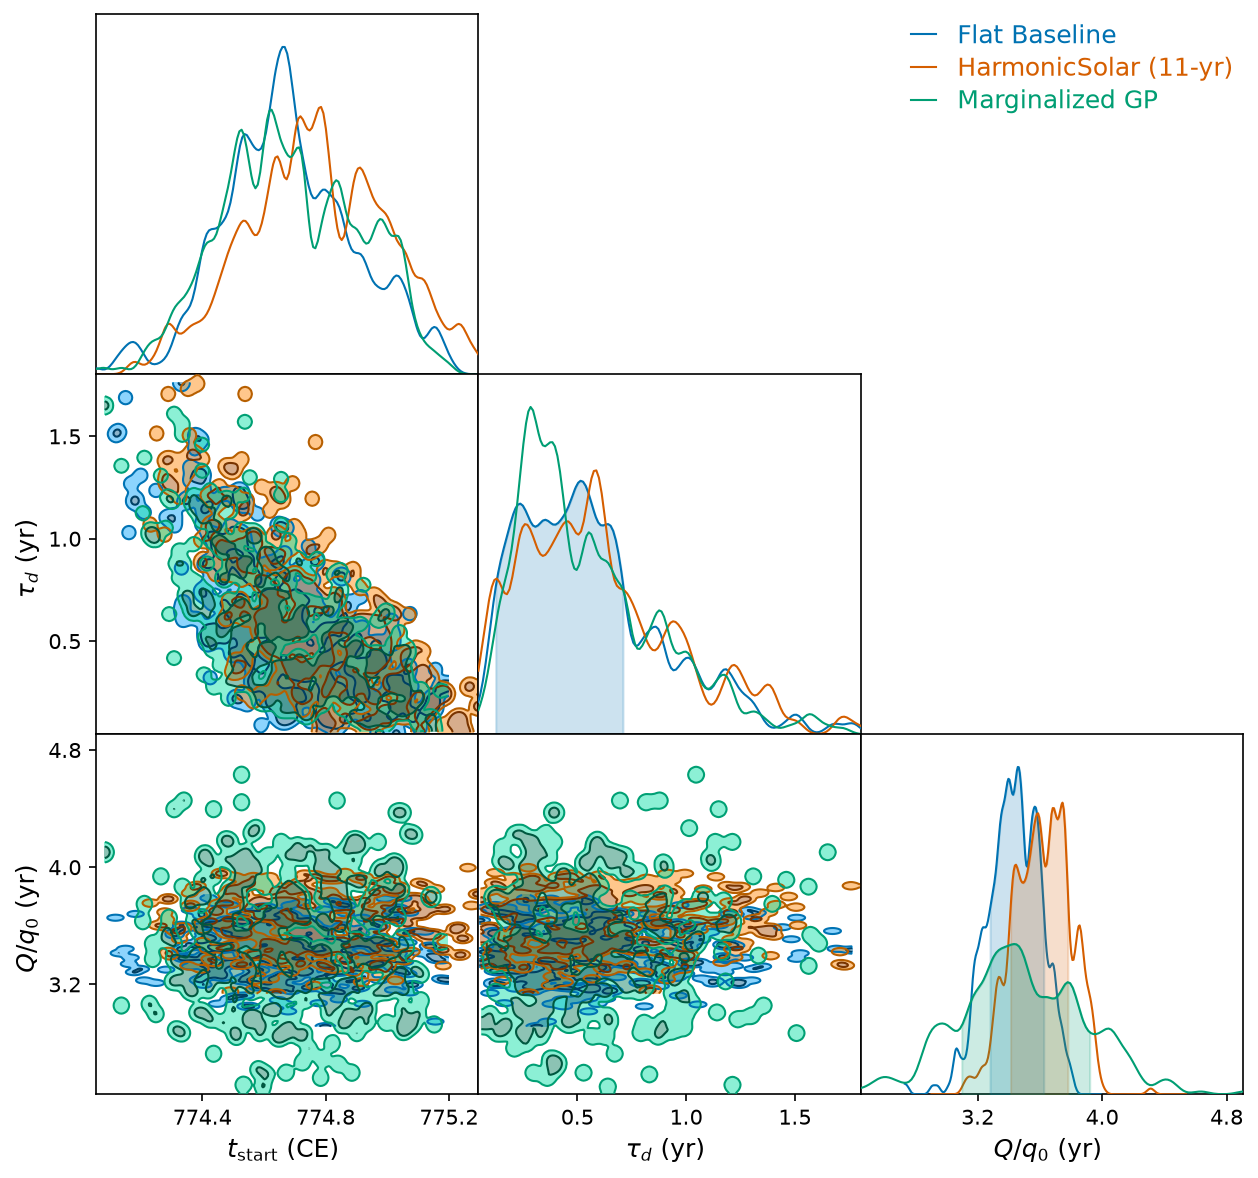

In [5]:
def _smc_dict(res):
    p = res.idata.posterior
    return {
        r"$t_{\mathrm{start}}$ (CE)": p["production__spike__t_start"].values.reshape(-1),
        r"$\tau_d$ (yr)": p["production__spike__duration"].values.reshape(-1),
        r"$Q / q_0$ (yr)": p["production__spike__fluence"].values.reshape(-1) / tt.DEFAULT_Q_STD,
    }
chains = {
    "Flat Baseline": _smc_dict(smc_flat),
    "HarmonicSolar (11-yr)": _smc_dict(smc_solar),
    "Marginalized GP": _smc_dict(smc_gp),
}
fig_corner, _ = tt.plot_corner(chains)

## One-to-One Observed vs Predicted Calibration

Comparing `Miyake12_Cedar` observations against the `Marginalized GP + Spike` posterior mean ring predictions via `plot_data_model_correlation` confirms unbiased `1:1` calibration with reduced $\chi^2 / N_{\mathrm{obs}}$ close to unity across the entire 28-ring record.

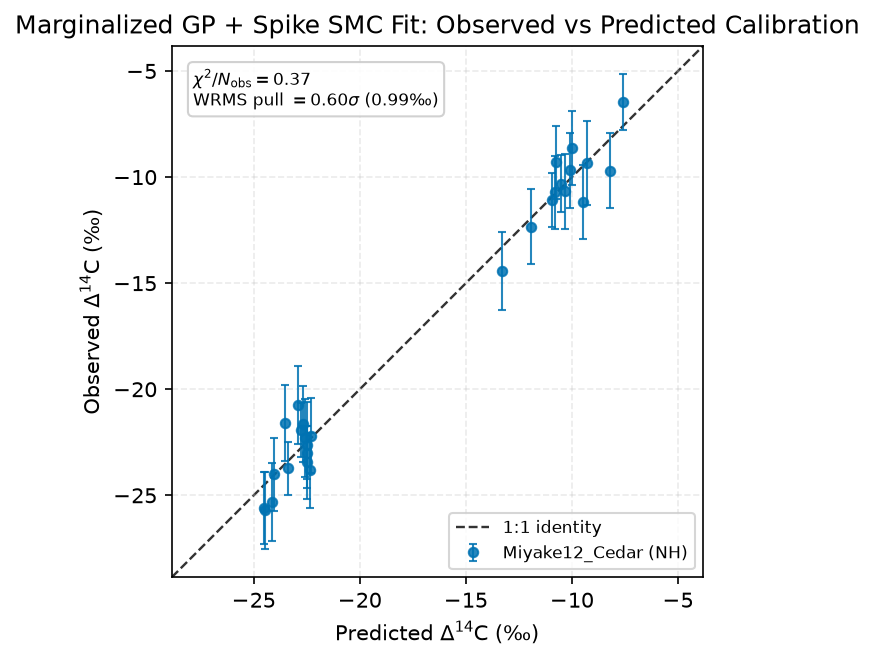

In [6]:
fig_corr, ax_corr = tt.plot_data_model_correlation(
    ds,
    lp_gp.ring_pred_mean,
    title="Marginalized GP + Spike SMC Fit: Observed vs Predicted Calibration",
)

Clamped Van Loan sub-interval quadrature (`ExactLinearSolver`) eliminates `v1`'s `adaptive=False, oversample=1008` constant-step workaround completely, while `BlackJAX` tempered SMC (`sample_smc`) paired with analytical `GaussianField` marginalization (`LinearMarginalConfig(marginalize_field=True)`) delivers calibrated three-way Bayes factors $\Delta\ln\widehat{Z}$ and multi-model `ChainConsumer` cornerplots in seconds.